# Phase 6.6 ? Fraud Model Explainability and Risk Interpretation

This notebook explains the Phase 6.5 provisional XGBoost champion using the same raw dataset, duplicate-removal helper, stratified 64/16/20 split, train-fitted feature engineering and model configuration. The validation partition selects the operating threshold; the held-out test set is used only for evaluation and post-fit explanations. SHAP values describe model behavior, not causal effects or verified business meanings.

## 1. Imports and reproducibility

The project source directory is added relative to the notebook, so this works when launched from the repository root or the `notebooks` directory. SHAP plotting uses an explicitly bounded sample.

In [1]:
import sys
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display

NOTEBOOK_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fraud_feature_engineering import clean_raw_fraud_data, split_fraud_data_stratified, FraudFeatureEngineer
from fraud_advanced_models import build_xgboost_fraud_model, find_best_advanced_threshold

RANDOM_STATE = 42
SHAP_SAMPLE_SIZE = 1000
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"SHAP {shap.__version__}; project root: {PROJECT_ROOT}")

SHAP 0.52.0; project root: C:\Users\Admin\banking-risk-intelligence-platform


## 2. Load, clean, split and engineer features

This repeats Phase 6.5 data preparation. The duplicate helper removes exact duplicates and resets the index. The split helper performs the same two-stage stratified split with `random_state=42`. `FraudFeatureEngineer.fit` sees only training features; its learned robust scaler is then applied to validation and test features.

In [2]:
data_path = PROJECT_ROOT / "data" / "raw" / "creditcard.csv"
if not data_path.exists():
    raise FileNotFoundError(f"Expected dataset at {data_path}")
df_raw = pd.read_csv(data_path)
df_clean = clean_raw_fraud_data(df_raw)
X_train_raw, X_val_raw, X_test_raw, y_train, y_val, y_test = split_fraud_data_stratified(
    df_clean, target_col="Class", train_ratio=0.64, val_ratio=0.16, test_ratio=0.20, random_state=RANDOM_STATE
)
feature_engineer = FraudFeatureEngineer(time_scaler="robust", preserve_original=True)
feature_engineer.fit(X_train_raw)
X_train = feature_engineer.transform(X_train_raw)
X_val = feature_engineer.transform(X_val_raw)
X_test = feature_engineer.transform(X_test_raw)

print(f"Raw rows: {len(df_raw):,}; cleaned rows: {len(df_clean):,}; removed duplicates: {len(df_raw)-len(df_clean):,}")
print(f"Train: {X_train.shape}, frauds={int(y_train.sum())}; validation: {X_val.shape}, frauds={int(y_val.sum())}; test: {X_test.shape}, frauds={int(y_test.sum())}")
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert "Class" not in X_train.columns
assert not X_train.isna().any().any() and not X_val.isna().any().any() and not X_test.isna().any().any()

Raw rows: 284,807; cleaned rows: 283,726; removed duplicates: 1,081
Train: (181584, 35), frauds=302; validation: (45396, 35), frauds=76; test: (56746, 35), frauds=95


## 3. Fit the fixed champion and lock its threshold on validation

The XGBoost configuration matches Phase 6.5 exactly. No parameters are tuned against test data. We reproduce Phase 6.5's validation F1 threshold sweep and use its selected threshold to label test outcomes.

In [3]:
model = build_xgboost_fraud_model(
    n_estimators=150, max_depth=7, learning_rate=0.05, subsample=0.8,
    colsample_bytree=0.8, scale_pos_weight=1.0, random_state=42, n_jobs=4
)
model.fit(X_train, y_train)
threshold, validation_f1, threshold_sweep = find_best_advanced_threshold(model, X_val, y_val)
print(f"Validation-selected threshold: {threshold:.2f}; validation F1: {validation_f1:.4f}")
test_probability = model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= threshold).astype(int)
test_results = pd.DataFrame({
    "actual": y_test.to_numpy(), "predicted": test_prediction, "fraud_probability": test_probability
}, index=X_test.index)
tp = int(((test_results.actual == 1) & (test_results.predicted == 1)).sum())
fp = int(((test_results.actual == 0) & (test_results.predicted == 1)).sum())
fn = int(((test_results.actual == 1) & (test_results.predicted == 0)).sum())
tn = int(((test_results.actual == 0) & (test_results.predicted == 0)).sum())
print(f"Held-out test confusion counts at threshold {threshold:.2f}: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

Validation-selected threshold: 0.35; validation F1: 0.9000
Held-out test confusion counts at threshold 0.35: TP=71, FP=2, FN=24, TN=56649


## 4. SHAP global explanations

`TreeExplainer` explains the trained XGBoost model. We sample up to 1,000 rows from the held-out test features with a fixed seed to keep the beeswarm and bar plots manageable. This sample is for explanation only; it does not refit, tune, or replace the test set. Mean absolute SHAP values rank average contribution magnitude. Positive SHAP values push the model output toward fraud; negative values push it toward legitimate. With the default raw model output, contributions are on the XGBoost margin (log-odds), not probability points.

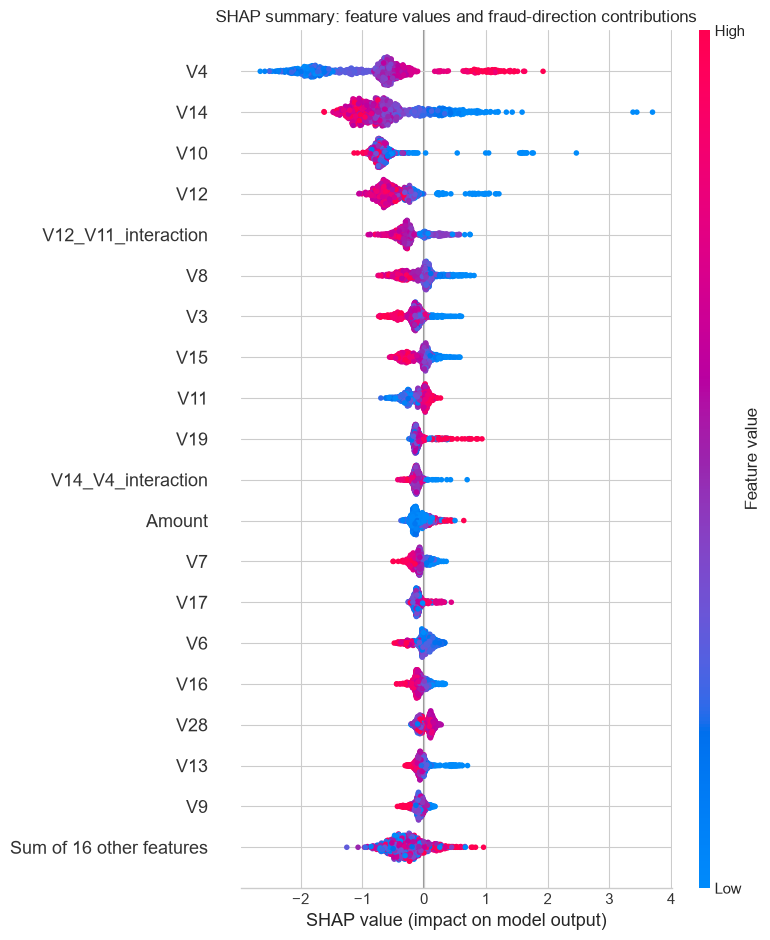

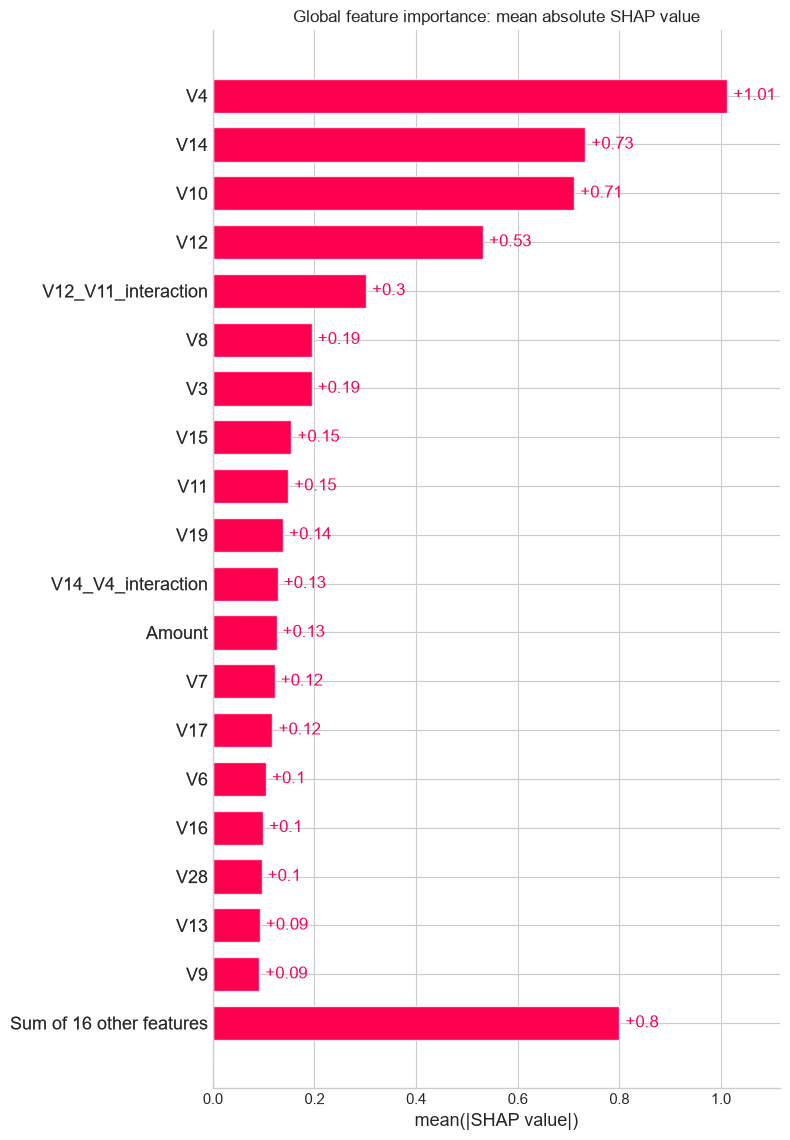

In [4]:
shap_sample = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(model)
shap_explanation = explainer(shap_sample)

# Normalize SHAP versions that return a class axis for binary classification.
values = shap_explanation.values
if values.ndim == 3:
    if values.shape[-1] == 2:
        values = values[:, :, 1]
    elif values.shape[1] == 2:
        values = values[:, 1, :]
    else:
        raise ValueError(f"Unexpected SHAP array shape: {values.shape}")
base_values = shap_explanation.base_values
if np.ndim(base_values) == 2:
    base_values = base_values[:, 1] if base_values.shape[-1] == 2 else base_values[:, 0]
explanation = shap.Explanation(
    values=values, base_values=base_values, data=shap_sample.to_numpy(), feature_names=list(shap_sample.columns)
)
assert values.shape == shap_sample.shape, (values.shape, shap_sample.shape)

plt.figure(figsize=(10, 8))
shap.plots.beeswarm(explanation, max_display=20, show=False)
plt.title("SHAP summary: feature values and fraud-direction contributions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
shap.plots.bar(explanation, max_display=20, show=False)
plt.title("Global feature importance: mean absolute SHAP value")
plt.tight_layout()
plt.show()

### Global ranking and comparison with Phase 6.5 XGBoost importance

The Phase 6.5 notebook compared XGBoost `feature_importances_` (the estimator's normalized importance, corresponding to its default split gain importance) across tree models. The table below places that ranking beside mean absolute SHAP magnitude. These measure different things: split gain summarizes training split utility, while SHAP measures average signed-output attribution magnitude on this sampled test subset.

In [5]:
shap_importance = pd.Series(np.abs(values).mean(axis=0), index=X_test.columns, name="mean_abs_shap")
xgb_importance = pd.Series(model.feature_importances_, index=X_test.columns, name="xgb_feature_importance")
importance_comparison = pd.concat([shap_importance, xgb_importance], axis=1)
importance_comparison["SHAP rank"] = importance_comparison["mean_abs_shap"].rank(ascending=False, method="min").astype(int)
importance_comparison["XGBoost rank"] = importance_comparison["xgb_feature_importance"].rank(ascending=False, method="min").astype(int)
importance_comparison = importance_comparison.sort_values("mean_abs_shap", ascending=False)
display(importance_comparison.head(15).round(6))
print("Top 10 features by mean absolute SHAP:", ", ".join(importance_comparison.head(10).index))

,mean_abs_shap,xgb_feature_importance,SHAP rank,XGBoost rank
V4,1.012452,0.029692,1,5
V14,0.732939,0.270444,2,1
V10,0.711164,0.257263,3,2
V12,0.531778,0.046826,4,4
V12_V11_interaction,0.301401,0.094448,5,3
V8,0.194554,0.012397,6,10
V3,0.194244,0.011482,7,12
V15,0.154401,0.008744,8,24
V11,0.148201,0.013693,9,7
V19,0.138195,0.007704,10,31


Top 10 features by mean absolute SHAP: V4, V14, V10, V12, V12_V11_interaction, V8, V3, V15, V11, V19


### Interpreting feature effects carefully

In the beeswarm, each dot is a sampled transaction. Color encodes that transaction's feature value; horizontal position gives its SHAP contribution. Values right of zero increase the model's fraud score, while values left of zero decrease it. The direction can vary across transactions because tree models learn nonlinear splits and interactions.

`V1`?`V28` are anonymized PCA-transformed components, so this notebook does not attach specific operational or customer meanings to them. `Amount_log` is `log1p(Amount clipped at zero)`, so larger values indicate larger nonnegative transaction amounts on a compressed scale; its SHAP direction remains model- and case-dependent. `is_zero_amount` indicates exactly zero amount. `Time_scaled` is time transformed using a robust scaler fitted on training time values. `V14_V4_interaction` and `V12_V11_interaction` are products of their named components; their effects cannot be interpreted as standalone real-world behaviors.

## 5. Local explanations for representative held-out transactions

For each confusion category, this selects the most confident qualifying held-out test example (highest fraud probability for TP/FP, lowest for FN/TN). The decision threshold is validation-selected. The waterfall explains the model margin for the selected individual: positive feature contributions move toward the fraud class and negative contributions toward legitimate. The base value plus contributions reconstructs that case's raw model output, subject to floating-point tolerance.

TP: test row index=41828, actual=1, predicted=1, probability=0.995800, threshold=0.35


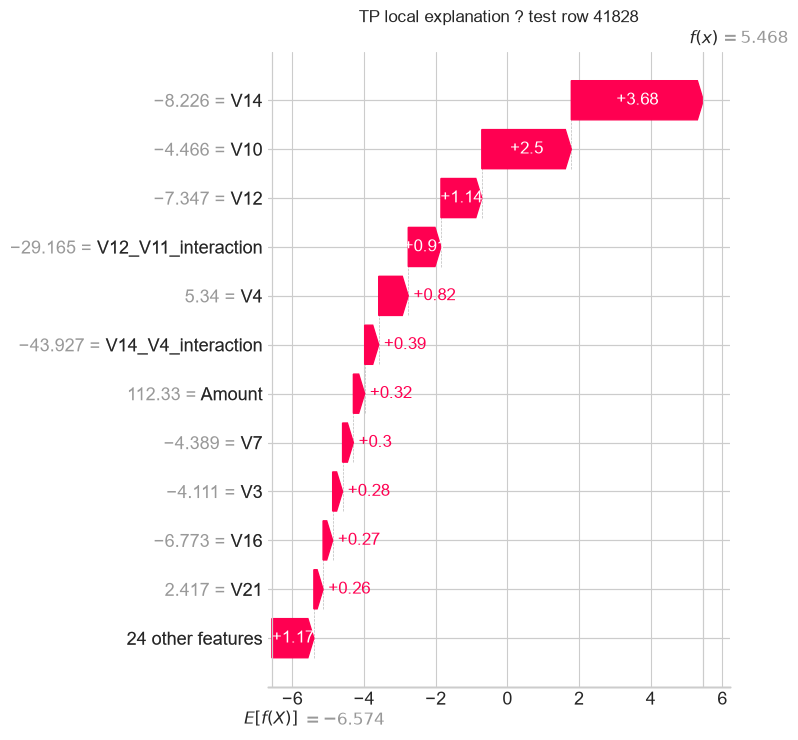

FP: test row index=119616, actual=0, predicted=1, probability=0.972888, threshold=0.35


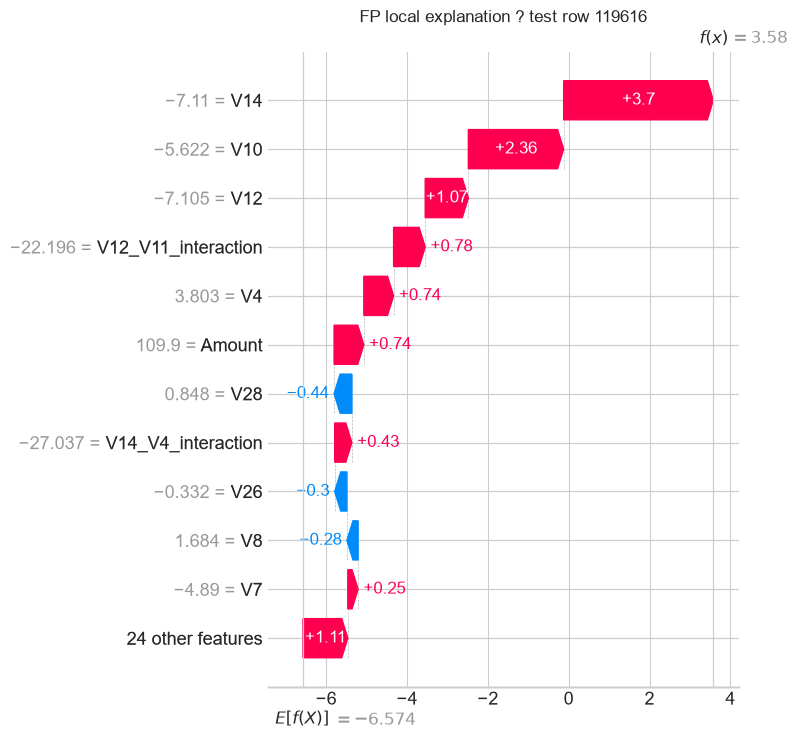

FN: test row index=68371, actual=1, predicted=0, probability=0.000015, threshold=0.35


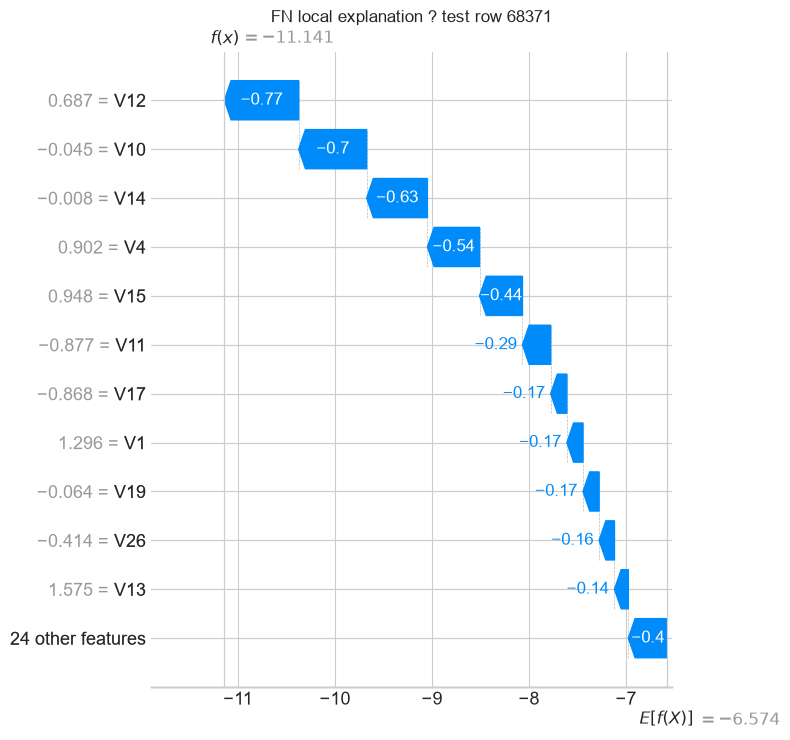

TN: test row index=109664, actual=0, predicted=0, probability=0.000003, threshold=0.35


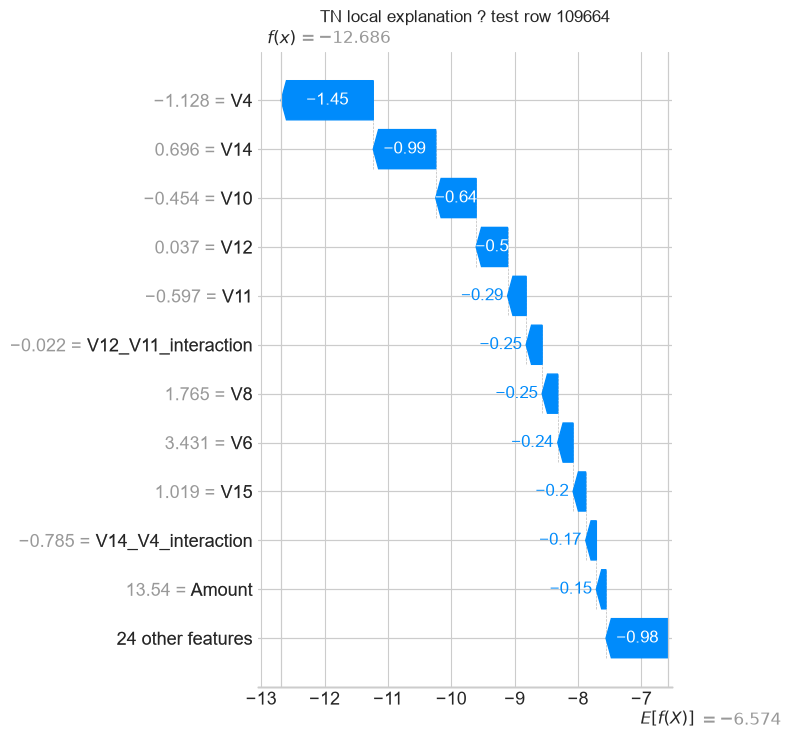

In [6]:
category_masks = {
    "TP": (test_results.actual == 1) & (test_results.predicted == 1),
    "FP": (test_results.actual == 0) & (test_results.predicted == 1),
    "FN": (test_results.actual == 1) & (test_results.predicted == 0),
    "TN": (test_results.actual == 0) & (test_results.predicted == 0),
}
selected_indices = {}
for category, mask in category_masks.items():
    candidates = test_results.loc[mask]
    if candidates.empty:
        print(f"{category}: no matching test cases; cannot show local example")
        continue
    # Most decisive example within its realized outcome category.
    selected = candidates.fraud_probability.idxmax() if category in ("TP", "FP") else candidates.fraud_probability.idxmin()
    selected_indices[category] = selected
local_rows = X_test.loc[list(selected_indices.values())]
local_explanation = explainer(local_rows)
local_values = local_explanation.values
if local_values.ndim == 3:
    local_values = local_values[:, :, 1] if local_values.shape[-1] == 2 else local_values[:, 1, :]
local_base = local_explanation.base_values
if np.ndim(local_base) == 2:
    local_base = local_base[:, 1] if local_base.shape[-1] == 2 else local_base[:, 0]
local_shap = shap.Explanation(
    values=local_values, base_values=local_base, data=local_rows.to_numpy(), feature_names=list(local_rows.columns)
)
for row_number, (category, row_index) in enumerate(selected_indices.items()):
    row = test_results.loc[row_index]
    print(f"{category}: test row index={row_index}, actual={int(row.actual)}, predicted={int(row.predicted)}, probability={row.fraud_probability:.6f}, threshold={threshold:.2f}")
    shap.plots.waterfall(local_shap[row_number], max_display=12, show=False)
    plt.title(f"{category} local explanation ? test row {row_index}")
    plt.tight_layout()
    plt.show()

## 6. Risk interpretation and operational context

A **positive** SHAP contribution raises the model's fraud score relative to its baseline output for that case; a **negative** contribution lowers it. Neither is a causal statement, nor does a large attribution establish a true fraud mechanism. Review the plots and ranking table to see the actual learned patterns, including direction and spread across transactions.

- **False positives** are legitimate transactions flagged for review or intervention. In operations they can create investigation workload, customer friction, or unnecessary declines. The local waterfall shows which model inputs pushed the chosen example across the threshold; it does not establish that those inputs are suspicious in a business sense.
- **False negatives** are fraud transactions left below the decision threshold. They represent missed detection exposure. Their waterfall highlights which inputs pulled the chosen case toward the legitimate prediction, but does not quantify monetary loss.
- **True positives** illustrate a correctly flagged fraud case; **true negatives** illustrate a correctly cleared legitimate case. One representative example per category is illustrative, not a population summary.

This model output is a score under a fixed model and threshold. It is not an adjudication, causal explanation, or calibrated estimate of financial loss.

## 7. Method and limitations

- Data source, duplicate handling, split ratios, random seed, feature engineering and champion hyperparameters match Phase 6.5. The validation partition alone selects the operating threshold; the test set remains held out for final evaluation and explanation.
- SHAP global plots use a fixed-seed sample of at most 1,000 test transactions. Ranking can vary with sample composition, and the rare fraud class is sparse in a simple random sample; the confusion-category local cases are selected separately from the full test set.
- Tree SHAP attributes this fitted model's output under its explainer assumptions. Correlated features and engineered interactions can share or redistribute attribution. Attributions are not causal, nor are they business explanations of anonymized PCA components.
- The model margin is not probability units. Binary-class SHAP output shape is normalized explicitly for library-version compatibility; feature labels are carried through from the transformed DataFrame.
- A single case per confusion category cannot characterize all outcomes. The notebook reports no synthetic examples and adds no dependencies beyond the already declared SHAP installation.